# Guide Colab : entraîner le modèle de tumeurs cérébrales

**Avant de commencer (à faire à la main, une seule fois) :**

1. **Exécution → Modifier le type d'exécution → GPU T4 → Enregistrer**
2. Panneau de gauche (icône dossier) → bouton d'upload → envoyer les 5 fichiers : `common.py`, `explore.py`, `gradcam.py`, `train.py`, `tune.py`
   (ils doivent apparaître directement dans `/content/`, à côté de `sample_data`)

Puis exécutez les cellules **dans l'ordre**, une par une (Maj + Entrée). Ne lancez pas la suivante tant que la précédente n'est pas terminée.

## Étape 1 : vérifier le GPU
Vous devez voir un `PhysicalDevice` de type GPU. Si la liste est vide `[]`, retournez à l'étape 1 ci-dessus.

In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Étape 2 : installer les dépendances manquantes

In [2]:
!pip install -q keras-tuner fpdf2 kagglehub

## Étape 3 : vérifier que les 5 fichiers sont bien là

In [3]:
import os
attendus = ["common.py", "explore.py", "gradcam.py", "train.py", "tune.py"]
for f in attendus:
    print(("OK       " if os.path.exists(f) else "MANQUANT ") + f)

OK       common.py
OK       explore.py
OK       gradcam.py
OK       train.py
OK       tune.py


## Étape 4 : télécharger le dataset
Le chemin affiché doit contenir `Training` et `Testing`.

In [4]:
import kagglehub, os
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Chemin :", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Chemin : /kaggle/input/brain-tumor-mri-dataset
['Training', 'Testing']


## Étape 5 : exploration du dataset

Training {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}
Testing {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400}
Tailles les plus fréquentes (échantillon) : [((512, 512), 589), ((225, 225), 40), ((630, 630), 11), ((236, 236), 8), ((192, 192), 7)]


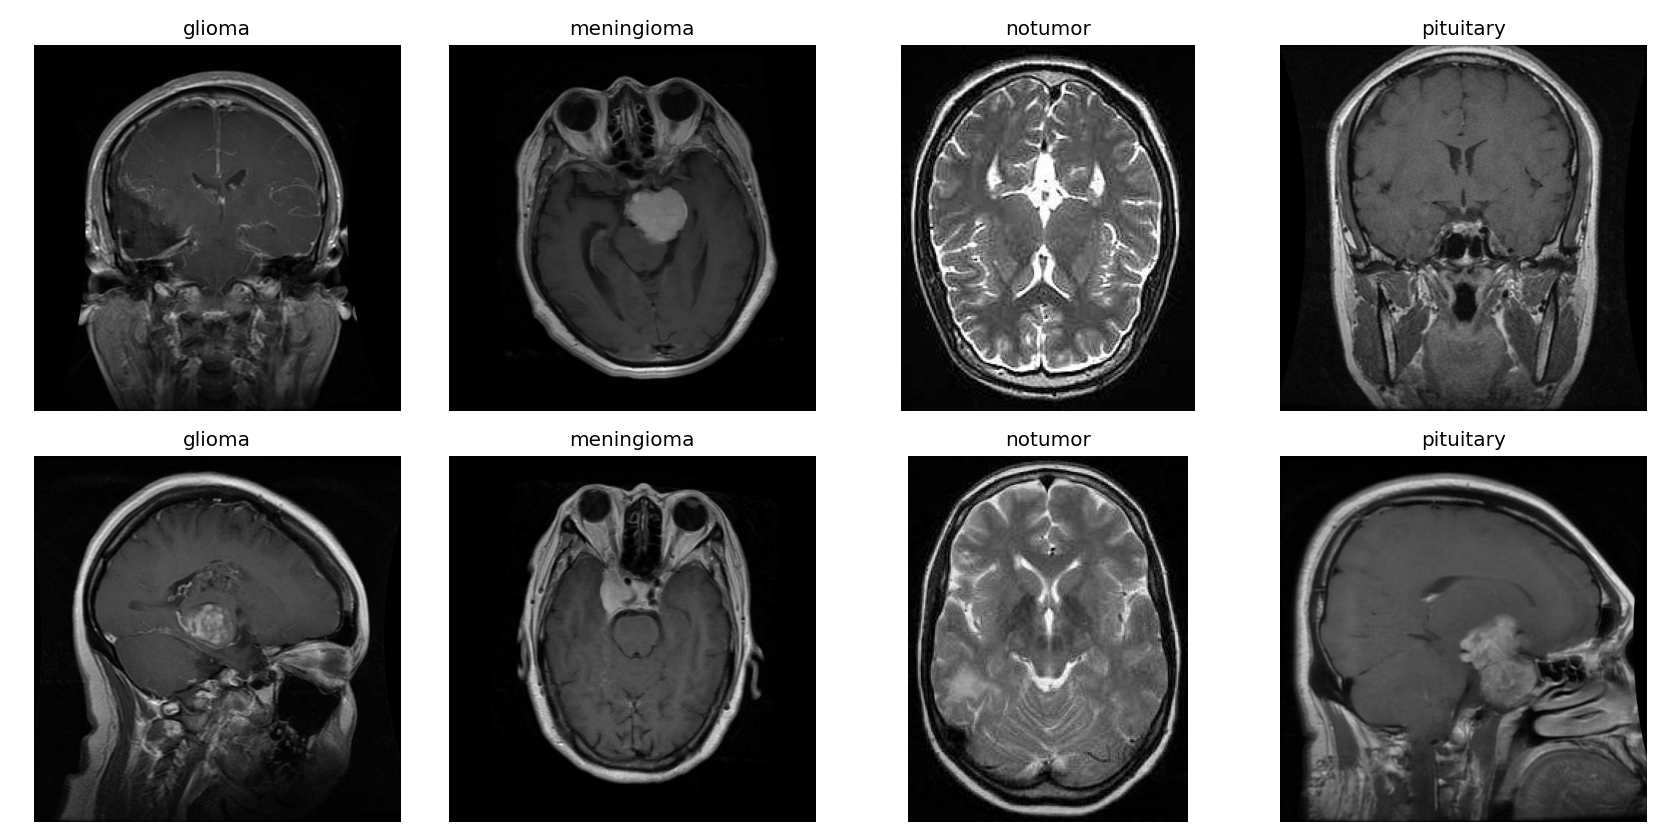

In [5]:
!python explore.py {path}
from IPython.display import Image, display
display(Image("exploration.png"))

## Étape 6 : entraînement du modèle de référence (baseline)
Crée `models/baseline/`.

In [6]:
!python train.py {path}

Found 5600 files belonging to 4 classes.
Using 4760 files for training.
W0000 00:00:1794497571.107969     863 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Found 5600 files belonging to 4 classes.
Using 840 files for validation.
Found 1600 files belonging to 4 classes.
Epoch 1/40
149/149 ━━━━━━━━━━━━━━━━━━━━ 48s 188ms/step - accuracy: 0.5782 - loss: 0.9599 - val_accuracy: 0.7667 - val_loss: 0.5947 - learning_rate: 0.0010
Epoch 2/40
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7739 - loss: 0.5912 - val_accuracy: 0.7964 - val_loss: 0.5082 - learning_rate: 0.0010
Epoch 3/40
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.8261 - loss: 0.4566 - val_accuracy: 0.8405 - val_loss: 0.4259 - learning_rate: 0.0010
Epoch 4/40
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8622 - loss: 0.3587 - val_accuracy: 0.8762 - val_loss: 0.3738 - learning_rate: 0.0010
Epoch 5

## Étape 7 (optionnelle) : raccourcir l'optimisation
`tune.py` fait 15 essais, ce qui est long. Cette cellule passe à 8 essais.

In [7]:
!sed -i 's/max_trials=15/max_trials=8/' tune.py
!grep max_trials tune.py

tuner = kt.BayesianOptimization(HM(), objective="val_accuracy", max_trials=8,


## Étape 8 : optimisation des hyperparamètres + comparaison
Crée `models/tuned/` et `comparison.png`.

Found 5600 files belonging to 4 classes.
Using 4760 files for training.
W0000 00:00:1794497693.582739    2682 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Found 5600 files belonging to 4 classes.
Using 840 files for validation.
Found 1600 files belonging to 4 classes.

Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
48                |48                |filters
0.2               |0.2               |dropout
0.00010528        |0.00010528        |lr

Epoch 1/12
297/298 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4359 - loss: 1.1606E0000 00:00:1794497725.385982    2732 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
298/298 ━━━━━━━━━━━━━━━━━━━━ 42s 91ms/step - accuracy: 0.5845 - loss: 0.9433 - val_accuracy: 0.7500 - val_loss: 0.6094
Epo

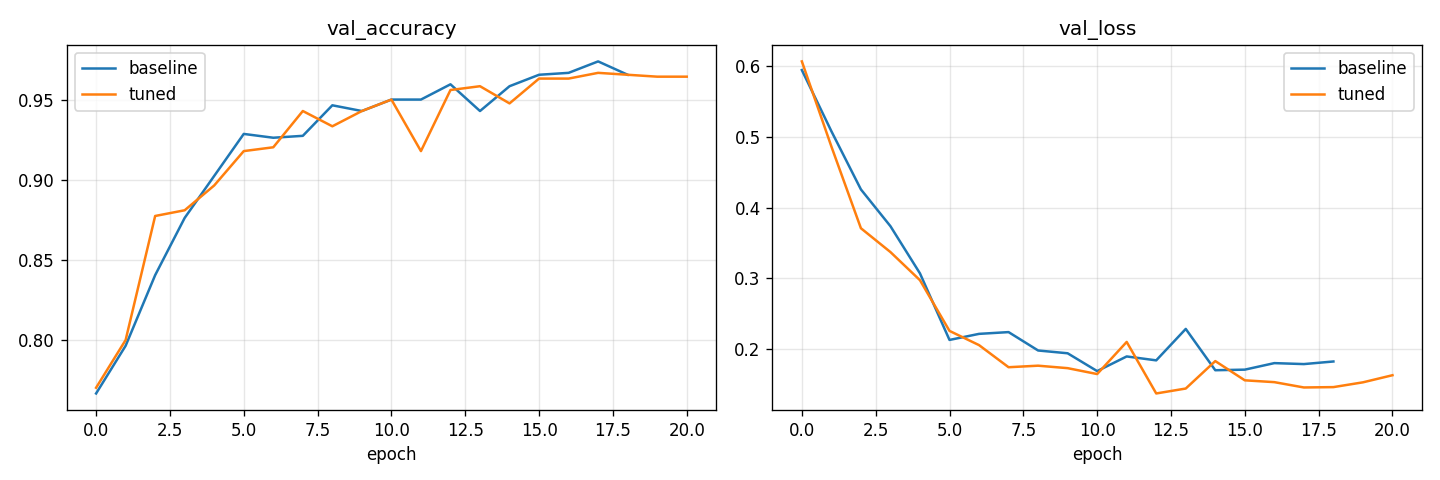

In [8]:
!python tune.py {path}
from IPython.display import Image, display
display(Image("comparison.png"))

## Étape 9 : récupération des résultats
Le zip contient `models/` (modèles + métriques + courbes + matrices de confusion), `exploration.png` et `comparison.png`.


In [9]:
!zip -r resultats.zip models exploration.png comparison.png
from google.colab import files
files.download("resultats.zip")

  adding: models/ (stored 0%)
  adding: models/baseline/ (stored 0%)
  adding: models/baseline/confusion_matrix.png (deflated 12%)
  adding: models/baseline/metrics.json (deflated 85%)
  adding: models/baseline/model.keras (deflated 22%)
  adding: models/baseline/curves.png (deflated 9%)
  adding: models/tuned/ (stored 0%)
  adding: models/tuned/confusion_matrix.png (deflated 11%)
  adding: models/tuned/metrics.json (deflated 85%)
  adding: models/tuned/model.keras (deflated 12%)
  adding: models/tuned/curves.png (deflated 8%)
  adding: exploration.png (deflated 2%)
  adding: comparison.png (deflated 7%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>